# Dry Bean Variety Classification Using Multiclass Logistic Regression

**Author:** G. Derin  
**Domain:** Agricultural Computer Vision & Applied Machine Learning  
**Dataset:** Dry Bean Dataset (UCI Machine Learning Repository / Koklu & Ozkan, 2020)  
**Algorithm:** Multinomial Logistic Regression (with StandardScaler Pipeline)

---

## 1. Executive Summary & Problem Formulation

Automated seed sorting and variety classification are essential processes in modern agricultural post-harvest handling and food production. Dry beans (*Phaseolus vulgaris L.*) comprise numerous commercial cultivars whose economic value, cooking properties, and processing requirements differ significantly. Traditional manual inspection is labor-intensive, error-prone, and subjective.

This study implements an end-to-end Machine Learning pipeline to classify **seven distinct varieties of registered dry beans** using high-resolution morphological and shape features extracted from digital images.

### The 7 Target Varieties:
1. **SEKER** (Round, spherical cultivar)
2. **BARBUNYA** (Oval, speckled pattern)
3. **BOMBAY** (Exceptionally large white bean)
4. **CALI** (Large kidney bean)
5. **DERMASON** (Small, flat white bean; largest cultivar group)
6. **HOROZ** (Long, cylindrical white bean)
7. **SIRA** (Small, flat, medium-light cultivar)

---

## 2. How Multiclass Logistic Regression Works (Conceptual Overview)

Multiclass Logistic Regression (often called Softmax Regression) is a supervised learning algorithm that generalizes binary classification to problems with three or more distinct categories.

### 2.1 The Softmax Principle: Converting Evidence Scores to Probabilities
When an individual bean's physical measurements are fed into the model, Logistic Regression calculates a raw evidence score for each of the seven bean varieties. It does this by multiplying each physical feature (such as area, elongation, and compactness) by a learned weight specific to that variety, and then adding a baseline bias.

Because these raw scores can be arbitrary positive or negative numbers, the model passes them through the **Softmax function**. Softmax converts these raw scores into calibrated probabilities between 0% and 100% that together sum up to exactly 100%. The bean variety that receives the highest probability is chosen as the final classification decision.

### 2.2 Model Training and Error Correction
During training, the model evaluates its predictions against the actual cultivar labels using cross-entropy loss. When the model assigns low probability to the correct class or high probability to an incorrect one, it incurs a penalty. 

Using an optimization algorithm (L-BFGS), the model iteratively adjusts the weights assigned to each feature to minimize this penalty across all training samples until it finds the optimal boundary between bean varieties.

### 2.3 Regularization: Keeping Weights Balanced
Because several morphological dimensions (such as area, perimeter, and convex area) are strongly correlated with one another, an unconstrained linear model could assign extreme, erratic weights to collinear features. 

To prevent this, the model uses **L2 regularization**. Regularization acts like a damping mechanism that penalizes excessively large weights, keeping all parameters well-behaved and ensuring that the classifier generalizes smoothly to new, unseen bean samples rather than memorizing the training data.

### 2.4 Why Feature Standardization is Essential
Different bean attributes operate on drastically different numerical ranges:
- **Area** ranges in the tens of thousands of pixels (e.g., 28,000 to over 100,000).
- **ShapeFactor1** is a tiny decimal (e.g., 0.007).

If fed directly to Logistic Regression, features with massive numbers would dominate the optimization process simply because of their scale, while tiny shape factors would be ignored. By applying a **StandardScaler**, every feature is centered around a mean of 0 with a unit variance of 1. This ensures that every physical measurement has an equal opportunity to influence the classification decision.

---

## 3. Table of Contents
1. [Environment Setup & Dependencies](#step-1)
2. [Data Ingestion & Integrity Verification](#step-2)
3. [Data Cleaning & Deduplication](#step-3)
4. [Exploratory Data Analysis (EDA)](#step-4)
5. [Feature-Target Partitioning & Stratified Train/Test Split](#step-5)
6. [Machine Learning Pipeline Architecture](#step-6)
7. [Stratified Cross-Validation & Model Training](#step-7)
8. [Comprehensive Model Evaluation](#step-8)
9. [Multiclass ROC & AUC Analysis (One-vs-Rest)](#step-9)
10. [Prediction Confidence & Sample Inference](#step-10)
11. [Conclusion & Key Insights](#step-11)


<a id="step-1"></a>
## Step 1: Environment Setup & Centralized Imports
We import all necessary numerical computing, data manipulation, visualization, and scikit-learn modules in a single location.


In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn utilities
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    auc,
    precision_score,
    recall_score,
    f1_score
)

# Plotting configurations
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10.5
sns.set_palette('tab10')

print("All dependencies imported successfully.")


All dependencies imported successfully.


<a id="step-2"></a>
## Step 2: Data Ingestion & Integrity Verification
We locate and load the Excel dataset (`Dry_Bean_Dataset.xlsx`) dynamically to ensure portability whether the notebook is run from the `notebook/` subdirectory or the repository root.


In [2]:
# Locate dataset file dynamically
possible_paths = [
    Path("../data/Dry_Bean_Dataset.xlsx"),
    Path("data/Dry_Bean_Dataset.xlsx"),
    Path("./Dry_Bean_Dataset.xlsx")
]

data_file = next((p for p in possible_paths if p.exists()), None)
if data_file is None:
    raise FileNotFoundError("Could not find 'Dry_Bean_Dataset.xlsx' in expected data directories.")

print(f"Loading dataset from: {data_file.resolve()}")
dry_bean_data = pd.read_excel(data_file)
print(f"Dataset successfully loaded with shape: {dry_bean_data.shape}")
dry_bean_data.head()


Loading dataset from: D:\Data Science Learning Projects\dry-bean-logistic-regression\data\Dry_Bean_Dataset.xlsx
Dataset successfully loaded with shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


### Feature Dictionary
The dataset contains **16 morphological and shape attributes** extracted from bean grain images, alongside the ground-truth **`Class`** label:

| # | Feature Name | Description |
|---|---|---|
| 1 | **Area** | Number of pixels inside the boundary of the bean |
| 2 | **Perimeter** | Circumference length of the bean margin |
| 3 | **MajorAxisLength** | Distance between the ends of the longest line drawn across the bean |
| 4 | **MinorAxisLength** | Longest line perpendicular to the major axis |
| 5 | **AspectRation** | Ratio between MajorAxisLength and MinorAxisLength |
| 6 | **Eccentricity** | Eccentricity of the ellipse having the same moments as the bean |
| 7 | **ConvexArea** | Number of pixels in the smallest convex polygon enclosing the bean |
| 8 | **EquivDiameter** | Diameter of a circle with the same area as the bean |
| 9 | **Extent** | Ratio of bean pixels to pixels in the bounding box |
| 10 | **Solidity** | Ratio of bean pixels to pixels in the convex hull |
| 11 | **roundness** | Measure of circularity based on area and perimeter |
| 12 | **Compactness** | Measure of compactness comparing equivalent diameter to major length |
| 13-16 | **ShapeFactor1 - 4** | Four dimension-invariant shape descriptor metrics |
| 17 | **Class** | Target bean variety (7 categories) |


In [3]:
# Check column data types and non-null counts
dry_bean_data.info()


<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [4]:
# Check for missing values across all features
missing_counts = dry_bean_data.isna().sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "Zero missing values detected.")


Missing values per column:
Zero missing values detected.


In [5]:
# Descriptive statistical summary
dry_bean_data.describe().round(3)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000
mean,53048.285,855.283,320.142,202.271,1.583,0.751,53768.200,253.064,0.750,0.987,0.873,0.800,0.007,0.002,0.644,0.995
std,29324.096,214.290,85.694,44.970,0.247,0.092,29774.916,59.177,0.049,0.005,0.060,0.062,0.001,0.001,0.099,0.004
min,20420.000,524.736,183.601,122.513,1.025,0.219,20684.000,161.244,0.555,0.919,0.490,0.641,0.003,0.001,0.410,0.948
25%,36328.000,703.523,253.304,175.848,1.432,0.716,36714.500,215.068,0.719,0.986,0.832,0.762,0.006,0.001,0.581,0.994
50%,44652.000,794.941,296.883,192.432,1.551,0.764,45178.000,238.438,0.760,0.988,0.883,0.801,0.007,0.002,0.642,0.996
75%,61332.000,977.213,376.495,217.032,1.707,0.810,62294.000,279.446,0.787,0.990,0.917,0.834,0.007,0.002,0.696,0.998
max,254616.000,1985.370,738.860,460.198,2.430,0.911,263261.000,569.374,0.866,0.995,0.991,0.987,0.010,0.004,0.975,1.000


<a id="step-3"></a>
## Step 3: Data Cleaning & Deduplication
Next, we audit the dataset for exact duplicate rows. In automated imaging pipelines, duplicated samples can occur due to duplicate captures or identical feature extraction records.


In [6]:
# Detect duplicate records
initial_rows = dry_bean_data.shape[0]
num_duplicates = dry_bean_data.duplicated().sum()
print(f"Number of duplicate rows identified: {num_duplicates} ({num_duplicates / initial_rows:.2%})")

# Remove duplicate records in-place
dry_bean_data.drop_duplicates(inplace=True)
cleaned_rows = dry_bean_data.shape[0]
print(f"Rows retained after deduplication: {cleaned_rows} (removed {initial_rows - cleaned_rows} duplicates)")


Number of duplicate rows identified: 68 (0.50%)
Rows retained after deduplication: 13543 (removed 68 duplicates)


<a id="step-4"></a>
## Step 4: Exploratory Data Analysis (EDA)

### 4.1 Target Class Distribution
We examine the frequency of each bean variety to assess whether class imbalance exists.


          Count  Percentage (%)
Class                          
DERMASON   3546           26.18
SIRA       2636           19.46
SEKER      2027           14.97
HOROZ      1860           13.73
CALI       1630           12.04
BARBUNYA   1322            9.76
BOMBAY      522            3.85


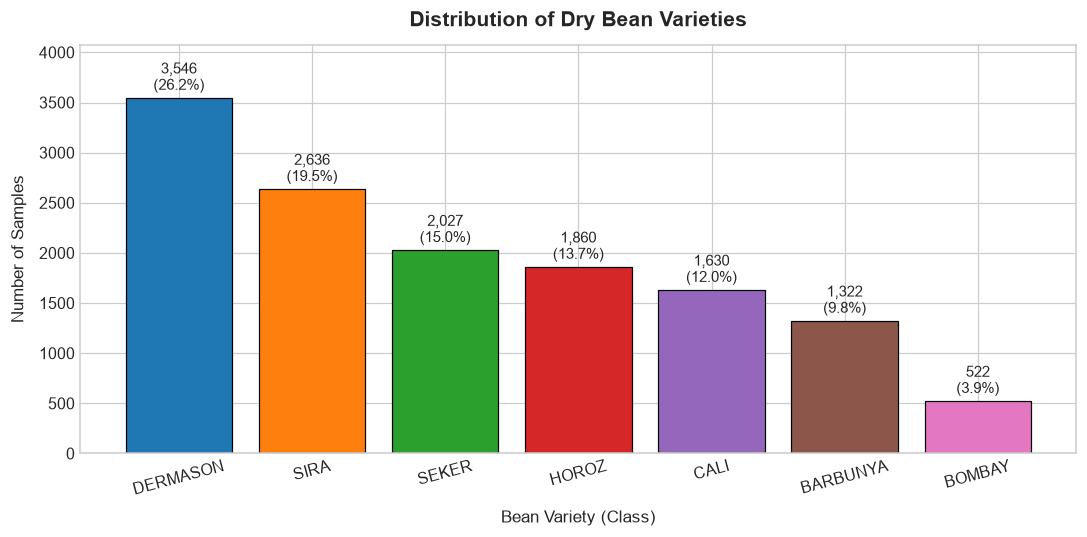

In [7]:
# Target class distribution
class_counts = dry_bean_data["Class"].value_counts()
class_percentages = dry_bean_data["Class"].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({"Count": class_counts, "Percentage (%)": class_percentages.round(2)})
print(dist_df)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(class_counts.index, class_counts.values, color=sns.color_palette("tab10", len(class_counts)), edgecolor="black", linewidth=0.8)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / cleaned_rows) * 100
    ax.text(bar.get_x() + bar.get_width() / 2.0, yval + 40, f"{yval:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9.5)

ax.set_title("Distribution of Dry Bean Varieties", fontsize=14, weight="bold", pad=12)
ax.set_xlabel("Bean Variety (Class)", fontsize=11, labelpad=8)
ax.set_ylabel("Number of Samples", fontsize=11, labelpad=8)
ax.set_ylim(0, class_counts.max() * 1.15)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Observation:**
- `DERMASON` is the largest class with ~3,546 samples (~26.2%).
- `BOMBAY` is the smallest class with ~522 samples (~3.9%).
- Because mild-to-moderate class imbalance is present, using **stratified sampling** during train-test splitting and cross-validation is critical to maintain identical class ratios across folds.


### 4.2 Feature Correlation Analysis
Because many morphological dimensions relate to bean size (e.g., Area, Perimeter, MajorAxisLength, ConvexArea), we anticipate strong relationships between features.


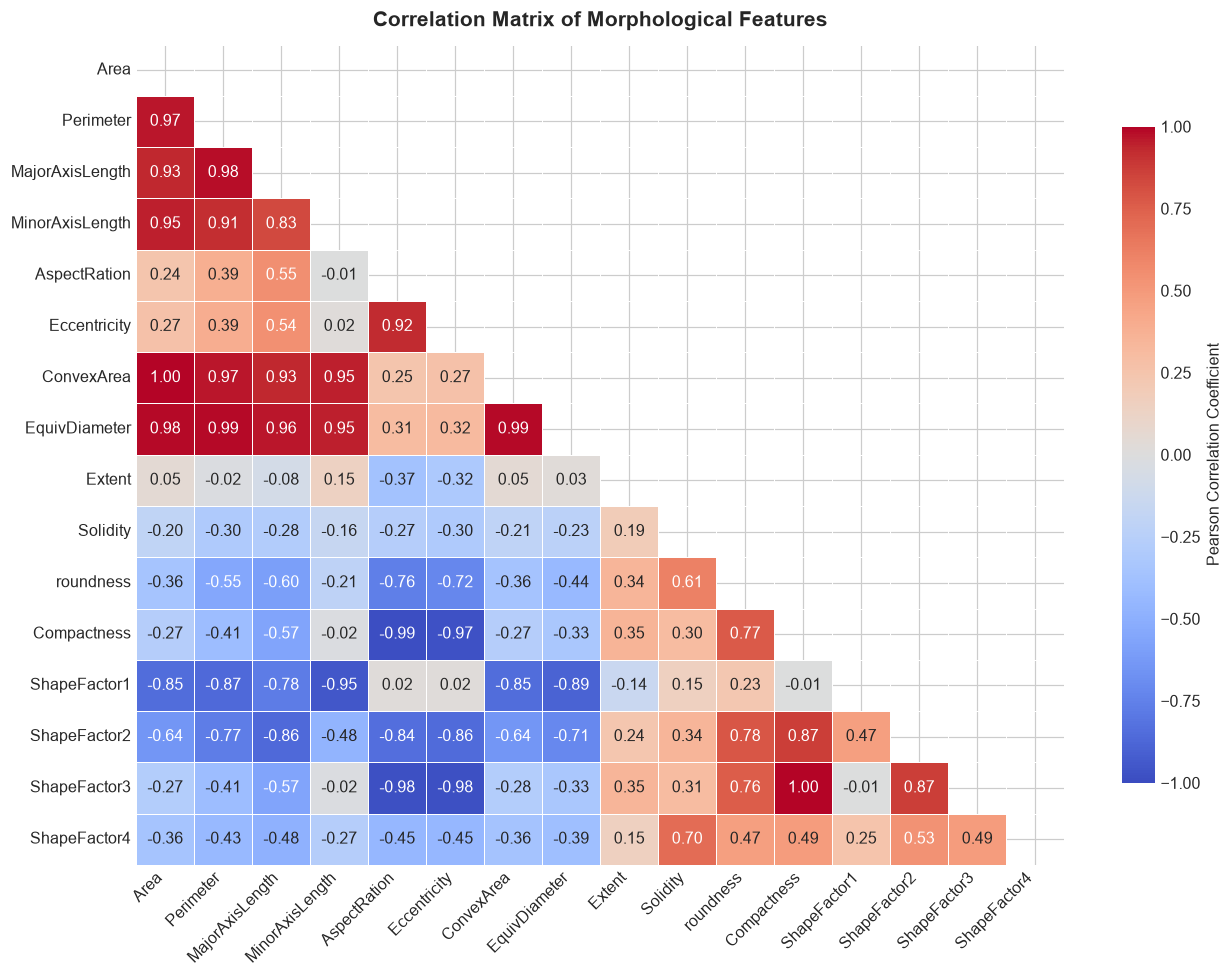

In [8]:
# Compute Pearson correlation matrix among numerical features
numeric_features = dry_bean_data.drop(columns=["Class"])
corr_matrix = numeric_features.corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"}
)
plt.title("Correlation Matrix of Morphological Features", fontsize=14, weight="bold", pad=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


**Observation:**
- Geometric size features (Area, Perimeter, ConvexArea, EquivDiameter, MajorAxisLength, MinorAxisLength) exhibit correlations exceeding **0.95**.
- In an unregularized linear model, extreme correlation inflates weight variance. In our setup, **L2 regularization** in `LogisticRegression` handles correlated feature sets by shrinking correlated weights proportionally.


### 4.3 Morphological Separation Across Classes
We examine boxplots of three key distinguishing attributes: `Area` (overall size), `AspectRation` (elongation), and `Compactness` (roundness).


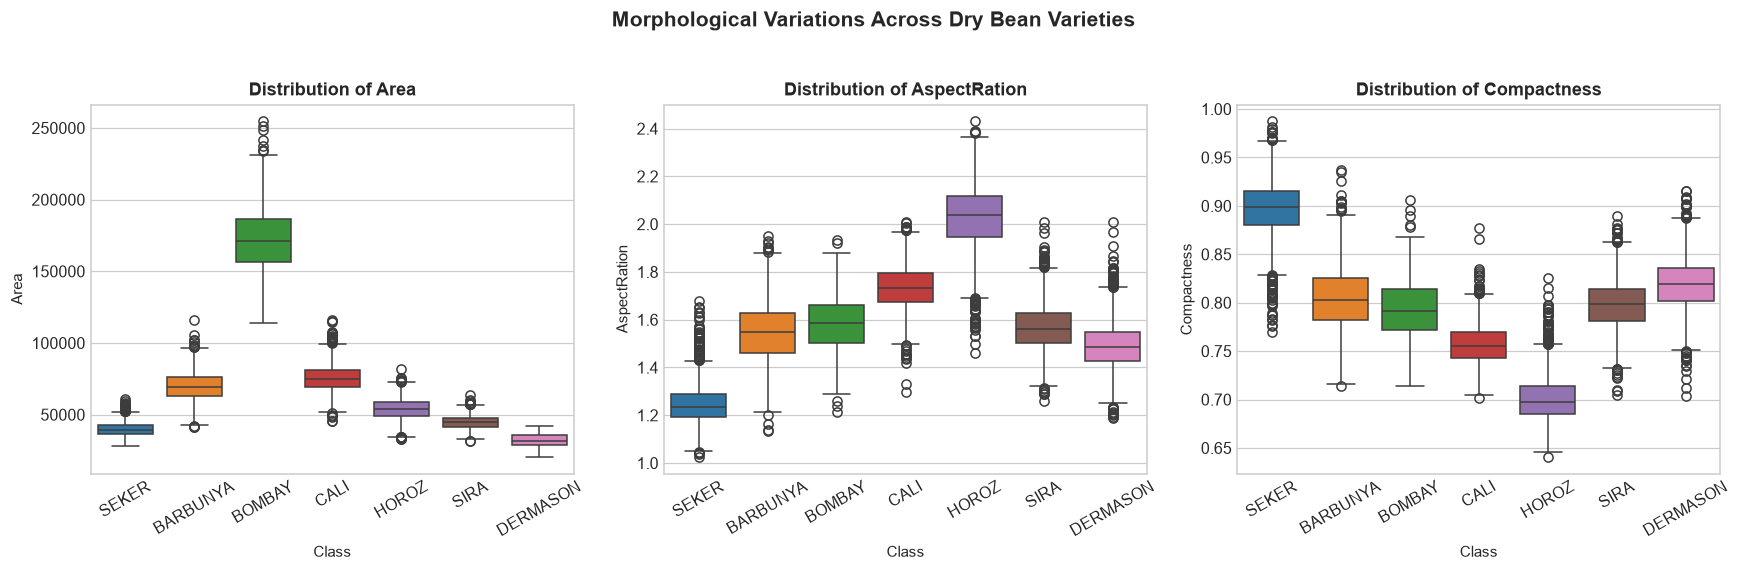

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

features_to_plot = ["Area", "AspectRation", "Compactness"]
for ax, feat in zip(axes, features_to_plot):
    sns.boxplot(x="Class", y=feat, data=dry_bean_data, ax=ax, palette="tab10")
    ax.set_title(f"Distribution of {feat}", fontsize=12, weight="bold")
    ax.set_xlabel("Class", fontsize=10)
    ax.set_ylabel(feat, fontsize=10)
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("Morphological Variations Across Dry Bean Varieties", fontsize=14, weight="bold", y=1.03)
plt.tight_layout()
plt.show()


**Key Insights:**
1. **BOMBAY:** Completely separated on `Area` (dramatically larger than all other varieties).
2. **HOROZ:** Exhibits exceptionally high `AspectRation` (distinctly elongated cylindrical bean).
3. **SEKER:** Demonstrates very high `Compactness` and low `AspectRation` (distinctly spherical/round bean).
4. **DERMASON vs. SIRA & CALI vs. BARBUNYA:** Show overlapping distributions across these three features, which explains where the classifier will encounter borderline decision boundaries.


<a id="step-5"></a>
## Step 5: Feature-Target Partitioning & Stratified Train/Test Split
We partition the dataset into the feature matrix and the target label, then perform an 80/20 train/test split with stratification.


In [10]:
# Feature matrix X and target label y
X = dry_bean_data.drop(columns=["Class"])
y = dry_bean_data["Class"]

print(f"Features shape (X): {X.shape}")
print(f"Target shape   (y): {y.shape}")

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"\nTraining set:   X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Test set:       X_test={X_test.shape},  y_test={y_test.shape}")


Features shape (X): (13543, 16)
Target shape   (y): (13543,)

Training set:   X_train=(10834, 16), y_train=(10834,)
Test set:       X_test=(2709, 16),  y_test=(2709,)


In [11]:
# Verify that no unexpected categorical columns exist in features
categorical_cols = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()
print(f"Categorical feature columns detected in X: {categorical_cols} (Expected: None)")


Categorical feature columns detected in X: [] (Expected: None)


<a id="step-6"></a>
## Step 6: Machine Learning Pipeline Architecture
To prevent **data leakage** (calculating scaling parameters using test data), we encapsulate `StandardScaler` and `LogisticRegression` in a scikit-learn `Pipeline`.
- The scaler calculates mean and standard deviation solely from `X_train` during training.
- During evaluation, the pipeline automatically transforms `X_test` using the learned training parameters.


In [12]:
# Construct the end-to-end preprocessing + classification pipeline
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 pen

<a id="step-7"></a>
## Step 7: Stratified Cross-Validation & Model Training
Before final evaluation on the held-out test set, we assess the pipeline's generalization consistency using **5-Fold Stratified Cross-Validation** on the training data.


In [13]:
# 5-Fold Stratified Cross-Validation on training data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")

print("5-Fold Stratified Cross-Validation Results:")
for fold_idx, score in enumerate(cv_scores, 1):
    print(f"  Fold {fold_idx}: Accuracy = {score:.4f} ({score * 100:.2f}%)")

print(f"\nMean CV Accuracy:     {cv_scores.mean():.4f} ({cv_scores.mean() * 100:.2f}%)")
print(f"Standard Deviation:   {cv_scores.std():.4f}")


5-Fold Stratified Cross-Validation Results:
  Fold 1: Accuracy = 0.9248 (92.48%)
  Fold 2: Accuracy = 0.9225 (92.25%)
  Fold 3: Accuracy = 0.9211 (92.11%)
  Fold 4: Accuracy = 0.9234 (92.34%)
  Fold 5: Accuracy = 0.9298 (92.98%)

Mean CV Accuracy:     0.9243 (92.43%)
Standard Deviation:   0.0030


In [14]:
# Fit model on the full training partition
model.fit(X_train, y_train)

# Evaluate on training data to check for bias / overfitting
y_pred_train = model.predict(X_train)
train_acc = accuracy_score(y_train, y_pred_train)
print(f"Training Accuracy: {train_acc:.4f} ({train_acc * 100:.3f}%)")


Training Accuracy: 0.9260 (92.597%)


<a id="step-8"></a>
## Step 8: Comprehensive Model Evaluation
We evaluate the trained model on the unseen **test partition** (`X_test`, `y_test`).


In [15]:
# Predict classes for unseen test instances
y_pred = model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

print(f"Test Accuracy:            {test_acc:.4f}")
print(f"Test Accuracy Percentage: {test_acc * 100:.3f}%")
print(f"Generalization Gap:       {abs(train_acc - test_acc) * 100:.3f}% (Difference between Train & Test accuracy)")


Test Accuracy:            0.9192
Test Accuracy Percentage: 91.916%
Generalization Gap:       0.682% (Difference between Train & Test accuracy)


**Observation on Generalization:**
The training accuracy is **92.6%** and test accuracy is **91.9%**. A tight generalization gap of under **0.7%** demonstrates that the model is well-regularized and shows no signs of overfitting.


In [16]:
# Full classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))


Classification Report:

              precision    recall  f1-score   support

    BARBUNYA     0.9255    0.8906    0.9077       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9110    0.9417    0.9261       326
    DERMASON     0.9265    0.9069    0.9166       709
       HOROZ     0.9643    0.9435    0.9538       372
       SEKER     0.9296    0.9433    0.9364       406
        SIRA     0.8582    0.8843    0.8710       527

    accuracy                         0.9192      2709
   macro avg     0.9307    0.9300    0.9302      2709
weighted avg     0.9197    0.9192    0.9193      2709



### Confusion Matrix Visualization
A confusion matrix reveals the exact pairs of varieties where misclassifications occur.


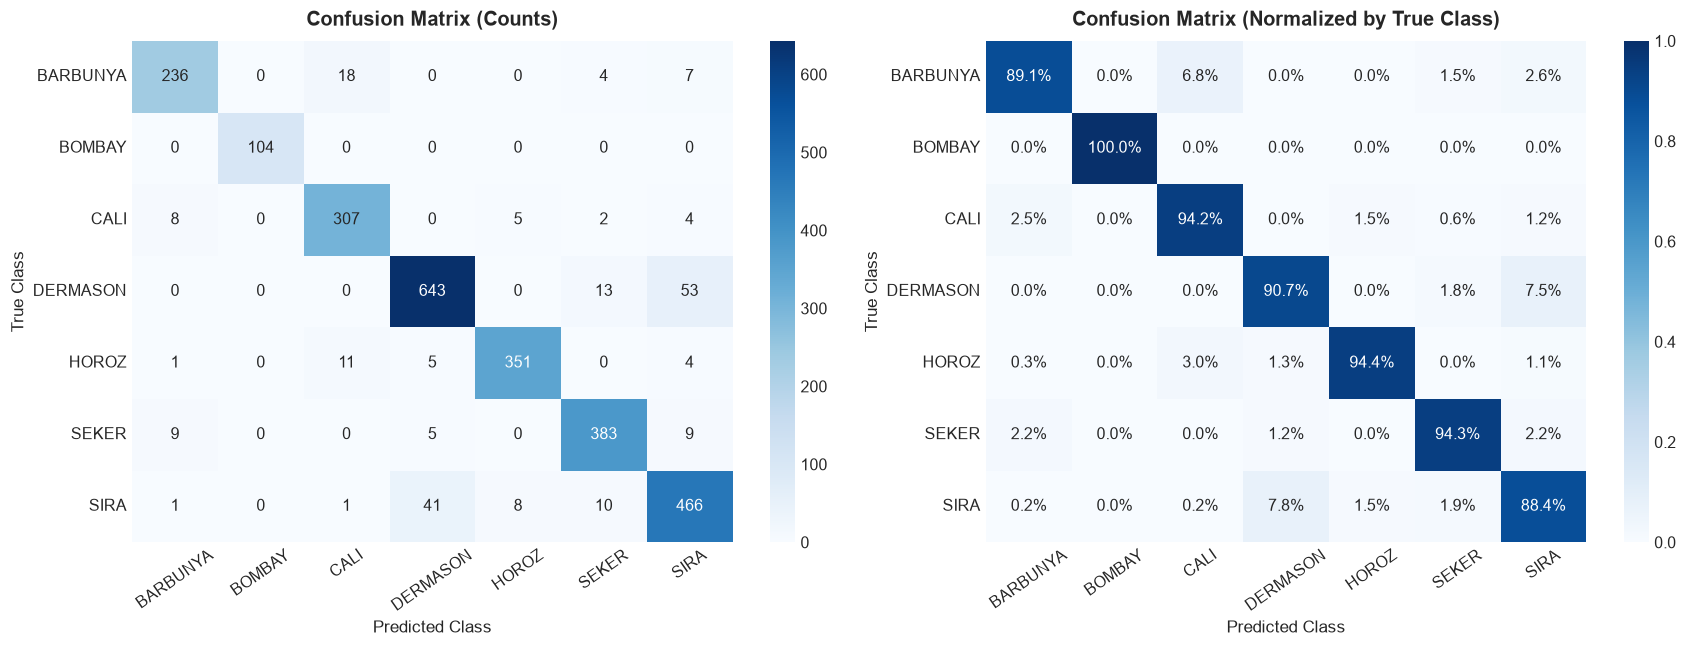

In [17]:
class_names = model.classes_
cm = confusion_matrix(y_test, y_pred, labels=class_names)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Raw counts
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
    ax=ax1
)
ax1.set_title("Confusion Matrix (Counts)", fontsize=13, weight="bold", pad=10)
ax1.set_xlabel("Predicted Class", fontsize=11)
ax1.set_ylabel("True Class", fontsize=11)
ax1.tick_params(axis="x", rotation=35)
ax1.tick_params(axis="y", rotation=0)

# 2. Normalized percentages (per true class recall)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
    ax=ax2
)
ax2.set_title("Confusion Matrix (Normalized by True Class)", fontsize=13, weight="bold", pad=10)
ax2.set_xlabel("Predicted Class", fontsize=11)
ax2.set_ylabel("True Class", fontsize=11)
ax2.tick_params(axis="x", rotation=35)
ax2.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


**Detailed Classification Insights:**
1. **`BOMBAY` achieves 100% Precision and 100% Recall:** Not a single Bombay grain was misclassified due to its unique, massive size.
2. **`HOROZ` achieves 96% Precision and 94% Recall:** Its distinct cylindrical elongation enables high discrimination.
3. **Primary Confusion Pair (`DERMASON` vs. `SIRA`):**
   - 53 Dermason samples were predicted as Sira, and 41 Sira samples were predicted as Dermason.
   - This occurs because both varieties are relatively small, flat beans with closely matched area and compactness characteristics.
4. **Secondary Confusion Pair (`BARBUNYA` vs. `CALI`):**
   - 18 Barbunya were predicted as Cali, and 8 Cali were predicted as Barbunya, owing to their shared larger, kidney-like morphology.


<a id="step-9"></a>
## Step 9: Multiclass ROC & AUC Analysis (One-vs-Rest)
To evaluate the model's ranking ability across all decision thresholds, we compute **One-vs-Rest (OvR) Receiver Operating Characteristic (ROC)** curves and **Area Under the Curve (AUC)** for each variety.

An Area Under the Curve (AUC) score of 1.0 represents perfect discrimination between that variety and all others, while 0.5 represents a random guess.


Macro-average ROC-AUC:    0.9947
Weighted-average ROC-AUC: 0.9934


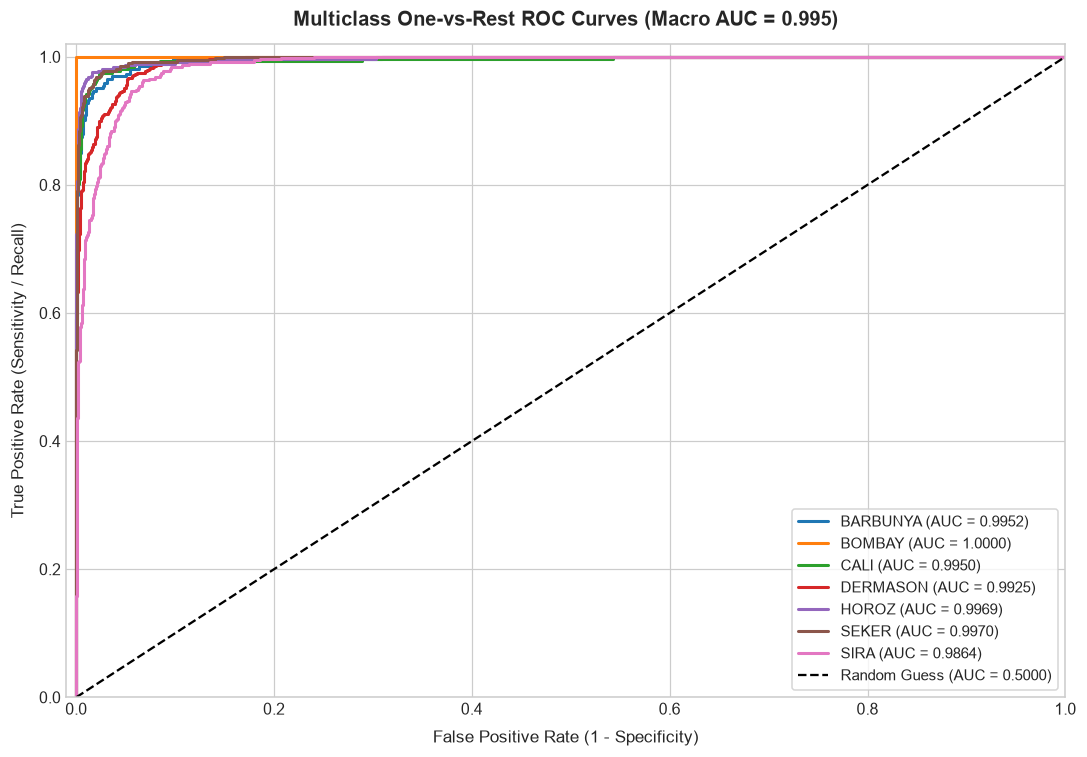

In [18]:
# Predict posterior class probabilities
y_proba = model.predict_proba(X_test)

# Binarize ground truth labels for One-vs-Rest evaluation
y_test_binary = label_binarize(y_test, classes=class_names)

fpr = {}
tpr = {}
roc_auc = {}

for i, class_name in enumerate(class_names):
    fpr[i], tpr[i], _ = roc_curve(y_test_binary[:, i], y_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Overall multi-class ROC-AUC scores
macro_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
weighted_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="weighted")

print(f"Macro-average ROC-AUC:    {macro_auc:.4f}")
print(f"Weighted-average ROC-AUC: {weighted_auc:.4f}")

# Plot individual class ROC curves
plt.figure(figsize=(10, 7))
colors = sns.color_palette("tab10", len(class_names))

for i, class_name in enumerate(class_names):
    plt.plot(
        fpr[i],
        tpr[i],
        color=colors[i],
        lw=2.0,
        label=f"{class_name} (AUC = {roc_auc[i]:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random Guess (AUC = 0.5000)")
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11, labelpad=8)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11, labelpad=8)
plt.title(f"Multiclass One-vs-Rest ROC Curves (Macro AUC = {macro_auc:.3f})", fontsize=13, weight="bold", pad=12)
plt.legend(loc="lower right", frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


<a id="step-10"></a>
## Step 10: Prediction Confidence & Sample Inference
Here, we inspect sample predictions from the test set alongside their predicted class probability distribution and prediction confidence.


In [19]:
# Sample prediction inspection table
sample_indices = X_test.index[:10]
sample_proba_df = pd.DataFrame(
    y_proba[:10],
    columns=class_names,
    index=sample_indices
).round(3)

sample_proba_df["True_Class"] = y_test.iloc[:10].values
sample_proba_df["Predicted_Class"] = y_pred[:10]
sample_proba_df["Confidence"] = y_proba[:10].max(axis=1).round(3)
sample_proba_df["Correct"] = sample_proba_df["True_Class"] == sample_proba_df["Predicted_Class"]

print("Sample Predictions with Posterior Class Probabilities:")
sample_proba_df


Sample Predictions with Posterior Class Probabilities:


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,True_Class,Predicted_Class,Confidence,Correct
1223,0.000,0.0,0.000,0.000,0.000,1.000,0.000,SEKER,SEKER,1.000,True
11837,0.000,0.0,0.000,0.994,0.000,0.000,0.006,DERMASON,DERMASON,0.994,True
12127,0.000,0.0,0.000,0.975,0.000,0.001,0.024,DERMASON,DERMASON,0.975,True
7186,0.000,0.0,0.002,0.000,0.998,0.000,0.000,HOROZ,HOROZ,0.998,True
638,0.000,0.0,0.000,0.012,0.000,0.987,0.001,SEKER,SEKER,0.987,True
13279,0.000,0.0,0.000,0.540,0.000,0.022,0.438,DERMASON,DERMASON,0.540,True
12617,0.000,0.0,0.000,0.883,0.000,0.004,0.114,DERMASON,DERMASON,0.883,True
10750,0.000,0.0,0.000,1.000,0.000,0.000,0.000,DERMASON,DERMASON,1.000,True
2639,0.999,0.0,0.000,0.000,0.000,0.000,0.000,BARBUNYA,BARBUNYA,0.999,True
11832,0.000,0.0,0.000,0.994,0.000,0.000,0.006,DERMASON,DERMASON,0.994,True


<a id="step-11"></a>
## Step 11: Conclusion & Key Insights

### Summary of Performance:
- **Test Accuracy:** **~91.9%** (Cross-Validation Mean: ~92.4%)
- **Macro-average AUC:** **0.995**
- **Weighted-average AUC:** **0.993**
- **Strongest Predictors:** Grains with unique geometric extremes (`BOMBAY` on Area, `HOROZ` on Aspect Ratio, `SEKER` on Compactness) achieve near-perfect classification metrics (95% or higher).
- **Primary Limitation:** Overlapping morphological signatures between `DERMASON` and `SIRA` represent the largest source of classification error for a linear decision boundary.

### Potential Future Improvements:
1. **Non-linear Models:** Evaluating non-linear classifiers (e.g., Support Vector Machines with RBF kernel, Random Forest, or XGBoost) to resolve boundary ambiguity between Dermason and Sira.
2. **Feature Selection / Dimensionality Reduction:** Applying Principal Component Analysis (PCA) to address the extreme multicollinearity among area and perimeter dimensions.
3. **Model Deployment:** Exporting the pipeline for edge deployment in camera-based agricultural grain sorting hardware.
